# Gaussian-process interpolation in energy of an uncertain ensemble $U(q,E)$

The profiles $U(q, E; \theta)$ depend on energy and but also have some uncertainty we don't know represented by $\theta$ (e.g., truncation, $\hbar \Omega$, $N_\text{max}$, etc.). We have only a $\theta$-marginal distribution; draws from $U(q, E; \theta) p(\theta)$.

We'll model each one with a Woods-Saxon shape:

$$
U(q, E; \theta) = U_0(E; \theta)\, f\big(q;\, R(E; \theta), a(E; \theta)\big), \qquad f(q; R, a) = \frac{1}{1 + e^{(q-R)/a}},
$$

on $q \in [0, q_{\max}]$, with $q_{\max}$ far enough beyond the surface that $U(q_{\max}) \approx 0$. We can compute profiles at a few energies $E_i$, for a set of draws $\theta_m$. The goal is **uncertainty quantified interpolation**, e.g. the $\theta$-marginal at new energies $E_\ast$,

$$
p\big(U(\cdot, E_\ast)\big) = \int p\big(U(\cdot, E_\ast; \theta)\big)\, p(\theta)\, d\theta ,
$$

meaning its mean, its spread, and how that spread is correlated in $q$.

**Approach.** At each $q$, fit a GP in $E$ to the ensemble mean, with the finite-sample error of that mean as noise. Then carry the full $\theta$ covariance, across both $E$ and $q$, to $E_\ast$ through the GP's weights.

## Primer: Gaussian processes

A GP, $f \sim \mathcal{GP}(m, k)$, is a distribution over functions. For any finite set of inputs $E_1, \dots, E_n$, the values $\big(f(E_1), \dots, f(E_n)\big)$ are jointly Gaussian, with mean $m(E_i)$ and covariance $K_{ij} = k(E_i, E_j)$. The kernel $k$ encodes the assumptions: amplitude, correlation length, smoothness.

**Conditioning:** Take observations $y_i = f(E_i) + \varepsilon_i$ with noise $\varepsilon \sim \mathcal N(0, \Sigma)$, $\Sigma = \mathrm{diag}(\delta_i^2)$ for independent errors. The formulas hold for any $\Sigma$; correlated errors use the full matrix, although sklearn's `alpha` only takes the diagonal. The posterior at some new $E_\ast$ that we want to interpolate (or extrapolate) to is Gaussian:

$$
\mu_\ast = m(E_\ast) + k(E_\ast, E_i)^\top (K + \Sigma)^{-1} (\mathbf y - \mathbf m),
\qquad
\sigma_\ast^2 = k(E_\ast, E_\ast) - k(E_\ast, E_i)^\top (K + \Sigma)^{-1} k(E_\ast, E_i),
$$

where $k(E_\ast, E_i)$ is the covariance between a training point $E_i$ and the new point $E_\ast$. The mean is a linear combination of the data. The variance shrinks near the data, by an amount set by the kernel and the noise.

**Hyperparameters:** The kernel parameters $\theta$ (amplitude $A$, length scale $\ell$) are fit by maximizing the log marginal likelihood, with $\mathbf r = \mathbf y - \mathbf m$:

$$
\log p(\mathbf y \mid \theta) = -\tfrac12\, \mathbf r^\top (K_\theta + \Sigma)^{-1} \mathbf r \;-\; \tfrac12 \log\lvert K_\theta + \Sigma\rvert \;-\; \tfrac n2 \log 2\pi .
$$

The first term rewards fitting the data, the second penalizes overly flexible models, such as a short $\ell$ that could fit anything, which helps avoid over-fitting.

**Matérn kernel:** With $r = \lvert E - E' \rvert$,

$$
k_\nu(r) = A\, \frac{2^{1-\nu}}{\Gamma(\nu)} \left(\frac{\sqrt{2\nu}\, r}{\ell}\right)^{\nu} K_\nu\!\left(\frac{\sqrt{2\nu}\, r}{\ell}\right).
$$

Sample paths are $\lceil\nu\rceil - 1$ times differentiable:

| $\nu$ | sample paths |
|---|---|
| $1/2$ | continuous but rough (exponential kernel) |
| $3/2$ | $C^1$ |
| $5/2$ | $C^2$ |
| $\infty$ | $C^\infty$ (RBF kernel) |

RBF tends to give overconfident bands between nodes when the truth is only finitely smooth, so we use $\nu = 5/2$.

### Exploring GP Kernels

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cho_solve
from scipy.optimize import minimize
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, RBF, ConstantKernel as C

warnings.filterwarnings(
    "ignore", category=ConvergenceWarning
)  # bound hits are expected for noise modes
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def prior_draws(kernel, x, n_draws, seed=7):
    # n_draws samples of f ~ GP(0, kernel) on the grid x
    L = np.linalg.cholesky(kernel(x[:, None]) + 1e-10 * np.eye(len(x)))
    return L @ np.random.default_rng(seed).standard_normal((len(x), n_draws))

#### Prior draws

Each curve is one draw $f(E) \sim \mathcal{GP}(0, k)$. Every kernel is fed the same random numbers, so differences between colours come only from the kernels. Solid and faded curves are two independent draws. On the left, the Matern $\nu$ parameter varies at fixed $\ell$: the paths get smoother but the wiggles keep their size. On the right, $\ell$ varies at fixed $\nu$: $\ell$ sets the correlation length.

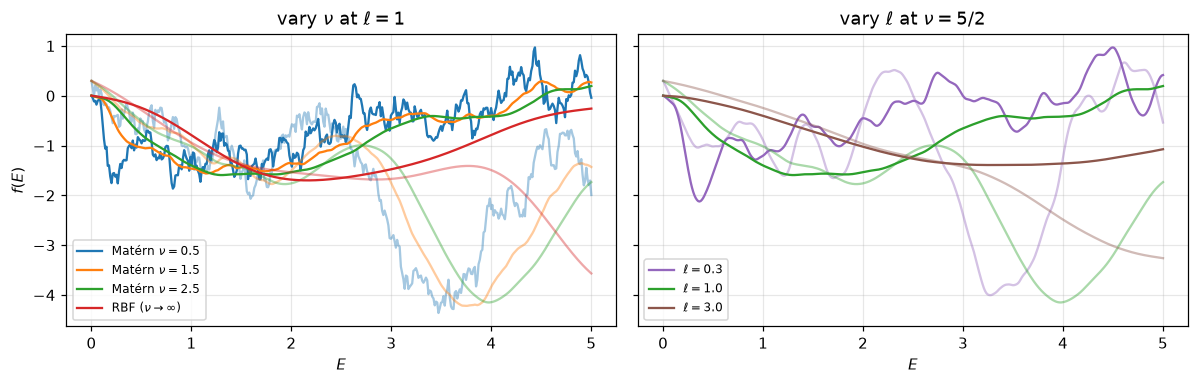

In [2]:
x = np.linspace(0, 5, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for nu, col in zip([0.5, 1.5, 2.5, np.inf], ["C0", "C1", "C2", "C3"]):
    k = RBF(1.0) if np.isinf(nu) else Matern(1.0, nu=nu)
    f = prior_draws(k, x, 2)
    ax[0].plot(
        x,
        f[:, 0],
        col,
        label=r"RBF ($\nu\to\infty$)" if np.isinf(nu) else rf"Matérn $\nu={nu}$",
    )
    ax[0].plot(x, f[:, 1], col, alpha=0.4)
for ell, col in zip([0.3, 1.0, 3.0], ["C4", "C2", "C5"]):
    f = prior_draws(Matern(ell, nu=2.5), x, 2)
    ax[1].plot(x, f[:, 0], col, label=rf"$\ell = {ell}$")
    ax[1].plot(x, f[:, 1], col, alpha=0.4)
ax[0].set_title(r"vary $\nu$ at $\ell = 1$")
ax[1].set_title(r"vary $\ell$ at $\nu = 5/2$")
ax[0].set_ylabel("$f(E)$")
for a in ax:
    a.set_xlabel("$E$")
    a.legend(fontsize=8)
plt.tight_layout()

### Conditioning on noisy data

`GaussianProcessRegressor(alpha=delta**2)` adds $\Sigma = \mathrm{diag}(\delta_i^2)$ to $K$, so every point carries its own error bar. Its hyperparameters are fit by maximizing the marginal likelihood.

What to look for:

- Posterior draws pass near the data, within the error bars, not through it.
- The band widens between and beyond the nodes.
- The band is wider around the point with the larger error bar.

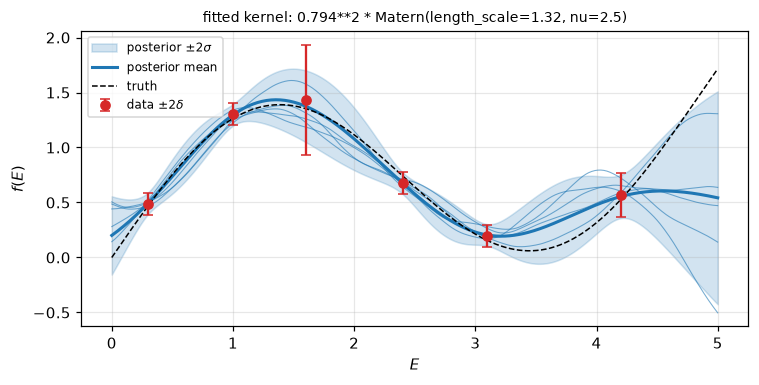

In [3]:
# Demo with an arbitrary true function
g = lambda E: np.sin(1.3 * E) + 0.3 * E


E_obs = np.array([0.3, 1.0, 1.6, 2.4, 3.1, 4.2])

# uncertainty at each point
d_obs = np.array([0.05, 0.05, 0.25, 0.05, 0.05, 0.10])

# synthetic data sampled with noise from around truth
y_obs = g(E_obs) + d_obs * np.random.default_rng(1).standard_normal(len(E_obs))

gpr = GaussianProcessRegressor(
    C(1.0) * Matern(1.0, nu=2.5), alpha=d_obs**2, n_restarts_optimizer=5, random_state=0
).fit(E_obs[:, None], y_obs)
mu, sd = gpr.predict(x[:, None], return_std=True)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.fill_between(
    x, mu - 2 * sd, mu + 2 * sd, color="C0", alpha=0.2, label=r"posterior $\pm 2\sigma$"
)
ax.plot(x, gpr.sample_y(x[:, None], 5, random_state=3), "C0", lw=0.7, alpha=0.6)
ax.plot(x, mu, "C0", lw=2, label="posterior mean")
ax.plot(x, g(x), "k--", lw=1, label="truth")
ax.errorbar(
    E_obs, y_obs, 2 * d_obs, fmt="o", color="C3", capsize=3, label=r"data $\pm 2\delta$"
)
ax.set_xlabel("$E$")
ax.set_ylabel("$f(E)$")
ax.legend(fontsize=8)
ax.set_title(f"fitted kernel: {gpr.kernel_}", fontsize=9)
plt.tight_layout()

## The toy problem: an ensemble over unknown parameters $\theta$

Three parameters $\theta = (\theta_{U_0}, \theta_{\dot R}, \theta_a)$ shift the energy dependencies of the depth, the radius grows with energy, and the diffuseness.

The same $\theta$ applies at every energy, so one draw of $\theta$ is one smooth family of profiles across $E$. The uncertainty is therefore correlated in $q$ (a draw moves a whole profile) and across $E$ (it moves every energy together).

**Data.** $M = 20$ draws $\theta_m$, each evaluated at the 7 training energies. From them we keep the ensemble mean and the sample covariance over $[E, q] \times [E, q]$:

$$
\bar U_i(q) = \frac1M \sum_m U(q, E_i; \theta_m), \qquad
C_{ik}(q, q') = \mathrm{Cov}_m\big[U(q, E_i; \theta_m),\ U(q', E_k; \theta_m)\big].
$$

Left: the members (thin) and their means. Right: at a surface point, the correlation of the $\theta$ spread between training energies. It is close to 1 everywhere, so the errors at different $E_i$ are far from independent.

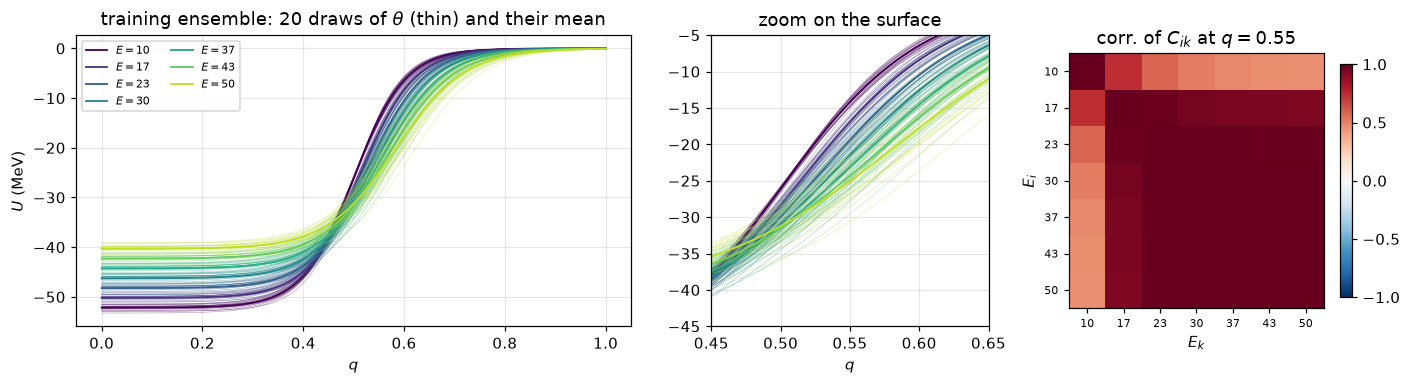

In [10]:
q = np.linspace(0, 1, 200)
SIG_THETA = np.array([0.01, 0.0005, 0.002])  # spread of (θ_U0, θ_Rdot, θ_a)


def sample_theta(M, seed=2):
    return SIG_THETA * np.random.default_rng(seed).standard_normal((M, 3))


def ws_params(E, theta):
    # (U0, R, a), each of shape (len(theta), len(E))
    E = np.atleast_1d(np.asarray(E, float))[None, :]
    dU0, dRdot, da = (theta[:, k : k + 1] for k in range(3))
    return (
        -(52.0 * (1 - dU0) - (0.3 + dU0) * (E - 10)) ,
        0.50 + (0.002 + dRdot) * (E - 10),
        0.050 + 0.0004 * (E - 10) + da,
    )


def U_theta(q, E, theta):
    # shape (len(theta), len(E), len(q))
    U0, R, a = (p[..., None] for p in ws_params(E, theta))
    return U0 / (1.0 + np.exp((q - R) / a))  # Woods-Saxon


def make_ensemble(E, M, seed=2):
    # members (M, n_E, n_q), their mean (n_E, n_q), sample covariance (n_E, n_q, n_E, n_q)
    members = U_theta(q, E, sample_theta(M, seed))
    X = (members - members.mean(0)).reshape(M, -1)
    Cov = (X.T @ X / (M - 1)).reshape(len(E), len(q), len(E), len(q))
    return members, members.mean(0), Cov


def score(mean, sd, draws):
    # RMS error of the mean, fraction of true draws within ±2σ, median sd ratio
    return (
        np.sqrt(np.mean((mean - draws.mean(0)) ** 2)),
        np.mean(np.abs(draws - mean) < 2 * sd),
        np.median(sd / draws.std(0)),
    )


M = 20
E_train = np.linspace(10, 50, 7)
E_test = np.array([13.0, 27.0, 44.0])
E_fine = np.linspace(5, 55, 200)
members, Ubar, Cov = make_ensemble(E_train, M)
truth_test = U_theta(q, E_test, sample_theta(20000, seed=99))  # draws of the true θ-marginal

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2, 1, 1.15]})
colors = plt.cm.viridis(np.linspace(0, 0.9, len(E_train)))
for i, (Ei, col) in enumerate(zip(E_train, colors)):
    for a in ax[:2]:
        a.plot(q, members[:, i].T, color=col, lw=0.4, alpha=0.4)
        a.plot(q, Ubar[i], color=col, lw=1.2, label=f"$E={Ei:.0f}$")
ax[0].set_title(rf"training ensemble: {M} draws of $\theta$ (thin) and their mean")
ax[0].legend(fontsize=7, ncol=2)
ax[1].set_xlim(0.45, 0.65)
ax[1].set_ylim(-45, -5)
ax[1].set_title("zoom on the surface")
ax[0].set_ylabel("$U$ (MeV)")
for a in ax[:2]:
    a.set_xlabel("$q$")
j_s = np.argmin(np.abs(q - 0.55))
Cj = Cov[:, j_s, :, j_s]
im = ax[2].imshow(Cj / np.outer(np.sqrt(np.diag(Cj)), np.sqrt(np.diag(Cj))), vmin=-1, vmax=1, cmap="RdBu_r")
ax[2].set_xticks(range(len(E_train)), [f"{e:.0f}" for e in E_train], fontsize=7)
ax[2].set_yticks(range(len(E_train)), [f"{e:.0f}" for e in E_train], fontsize=7)
ax[2].set_xlabel("$E_k$")
ax[2].set_ylabel("$E_i$")
ax[2].grid(False)
ax[2].set_title(f"corr. of $C_{{ik}}$ at $q = {q[j_s]:.2f}$")
fig.colorbar(im, ax=ax[2], shrink=0.8)
plt.tight_layout()

## Pointwise GP fit to the ensemble mean, then propagation

**Two pieces.** Write each member as $U(q, E; \theta) = m(q, E) + g(q, E; \theta)$. Here $m = \mathbb E_\theta[U]$ is the ensemble mean, a smooth deterministic function of $E$, and $g$ is the $\theta$ deviation, with covariance $C$. The prediction at $E_\ast$ needs both: where $m(E_\ast)$ is, and how wide $g(E_\ast)$ is.

**Fit: the GP learns $m$.** At each $q_j$ we fit a GP in $E$ to the ensemble means $\bar U_{ij}$. These differ from $m(q_j, E_i)$ only because $M$ is finite. Their error has covariance $C^{(j)}/M$, with $C^{(j)}_{ik} = C_{ik}(q_j, q_j)$. In the fit we use its diagonal, $D^{(j)} = \mathrm{diag}\big(C^{(j)}\big)/M$. As before, each column is standardized by its mean $\mu_j$ and standard deviation $s_j$ over the training energies:

$$
\frac{\bar{\mathbf U}_{:,j} - \mu_j}{s_j} \;\sim\; \mathcal N\!\Big(0,\; K_\theta + \frac{D^{(j)}}{s_j^2}\Big),
\qquad K_\theta = A\cdot\mathrm{Matern}_{5/2}(\ell).
$$

**The prediction is a weighted sum.** With fixed hyperparameters, the GP mean is linear in the data:

$$
\hat m(q_j, E_\ast) = \sum_i w_i(q_j, E_\ast)\, \bar U_{ij}, \qquad
\mathbf w = \boldsymbol\beta + \frac{1 - \mathbf 1^\top \boldsymbol\beta}{n_E}\,\mathbf 1, \qquad
\boldsymbol\beta = \Big(K_\theta + \frac{D^{(j)}}{s_j^2}\Big)^{-1} \mathbf k_\ast .
$$

The second term in $\mathbf w$ comes from the column-mean prior mean. The weights depend on $q$ through the noise.

**Propagate.** Applying the same weights to every member, $\hat U_m(q, E_\ast) = \sum_i w_i\, U(q, E_i; \theta_m)$, gives an interpolated ensemble. Its mean is $\hat m$, and the predictive covariance for a new draw of $\theta$ is

$$
\mathrm{Cov}\big[U(q, E_\ast),\, U(q', E_\ast)\big] \approx
\underbrace{\Big(1 + \frac1M\Big) \sum_{i,k} w_i(q)\, w_k(q')\, C_{ik}(q, q')}_{\theta \text{ spread, and the error of } \bar U}
\;+\; \underbrace{\delta_{qq'}\, \sigma^2_{\mathrm{GP}}(q, E_\ast)}_{\text{GP latent variance}} .
$$

- **First term.** The 1 carries the $\theta$ spread of a new draw to $E_\ast$, through the cross-energy blocks $C_{ik}$ and with its full $q$–$q'$ correlation. It assumes the deviations $g$ are as easy to interpolate as $m$. The $1/M$ is the error of $\bar U$, which has the same structure: $\hat m$ is built from $\bar U$ with the same weights.
- **Second term.** This is the GP's own uncertainty: interpolation error, plus the diagonal part of the mean's error again, which makes the band slightly conservative. The pointwise GP has no model of how interpolation errors correlate across $q$, so this term is diagonal.

In [11]:
def default_kernel():
    return C(1.0, (1e-2, 1e2)) * Matern(20.0, (2.0, 1e3), nu=2.5)


class PointwiseGP:
    # One sklearn GP in E per q column, with shared hyperparameters

    def __init__(self, kernel=None, thin=20):
        self.kernel = kernel if kernel is not None else default_kernel()
        self.thin = thin

    def _fit_column(self, j, kernel):
        mu, s = self.Y[:, j].mean(), self.Y[:, j].std()
        gpr = GaussianProcessRegressor(kernel, alpha=self.var[:, j] / s**2, optimizer=None)
        return gpr.fit(self.E, (self.Y[:, j] - mu) / s), mu, s

    def fit(self, E, Y, var):
        # Y: data (n_E, n_q); var: variance of its errors (n_E, n_q)
        self.E, self.Y, self.var = np.asarray(E, float)[:, None], Y, var
        pool = [self._fit_column(j, self.kernel)[0] for j in range(0, Y.shape[1], self.thin)]

        def neg_mean_lml(theta):
            lml, grad = zip(*(g.log_marginal_likelihood(theta, eval_gradient=True) for g in pool))
            return -np.mean(lml), -np.mean(grad, axis=0)

        res = minimize(neg_mean_lml, self.kernel.theta, jac=True, method="L-BFGS-B", bounds=self.kernel.bounds)
        self.kernel_ = self.kernel.clone_with_theta(res.x)
        self.columns = [self._fit_column(j, self.kernel_) for j in range(Y.shape[1])]
        return self

    def predict(self, Es):
        # GP mean and latent sd, each (len(Es), n_q), and weights W (len(Es), n_E, n_q): mean = Σ_i W_i Y_i
        Es = np.atleast_1d(np.asarray(Es, float))[:, None]
        ks, n = self.kernel_(self.E, Es), len(self.E)
        W = np.empty((len(Es), n, len(self.columns)))
        sd = np.empty((len(Es), len(self.columns)))
        for j, (gpr, mu, s) in enumerate(self.columns):
            beta = cho_solve((gpr.L_, True), ks)  # (K + alpha)^-1 k*, from sklearn's Cholesky factor
            W[:, :, j] = (beta + (1 - beta.sum(0)) / n).T
            sd[:, j] = s * gpr.predict(Es, return_std=True)[1]
        return np.einsum("sij,ij->sj", W, self.Y), sd, W


def propagate(W, Cov):
    # θ covariance carried to each E*: Σ_ik w_i(q) w_k(q') Cov_ik(q, q'), shape (len(W), n_q, n_q)
    return np.einsum("siq,iqkr,skr->sqr", W, Cov, W, optimize=True)


def propagate_var(W, Cov):
    # diagonal of propagate(W, Cov), shape (len(W), n_q)
    return np.einsum("siq,ikq,skq->sq", W, np.einsum("iqkq->ikq", Cov), W)


gp = PointwiseGP().fit(E_train, Ubar, np.einsum("iqiq->iq", Cov) / M)
mean_test, sd_gp_test, W_test = gp.predict(E_test)
cov_test = (1 + 1 / M) * propagate(W_test, Cov) + sd_gp_test[:, :, None] ** 2 * np.eye(len(q))
sd_test = np.sqrt(np.einsum("sqq->sq", cov_test))
print("fitted kernel:", gp.kernel_)

# the members pushed through the weights have exactly the propagated covariance
pushed = np.einsum("siq,miq->msq", W_test, members)
print("check: max |propagated − cov of pushed members| =",
      np.abs(propagate(W_test, Cov)[1] - np.cov(pushed[:, 1].T)).max())

fitted kernel: 3.7**2 * Matern(length_scale=85.2, nu=2.5)
check: max |propagated − cov of pushed members| = 4.884981308350689e-15


### Slices at fixed $q$

This is the interpolation problem itself, solved at every $q$. Each panel shows:

- **red:** the training members, one line per $\theta_m$;
- **dark band:** the GP latent band, which covers the mean $m$ only;
- **light band:** the total band, after adding the propagated $\theta$ spread;
- **black:** the true $\theta$-marginal, mean $\pm 2\sigma$.

In the interior, $U(E)$ tracks $U_0(E)$ and is close to linear. At the surface it is sigmoid-like, because the edge sweeps past a fixed $q$ as $E$ changes. The $\theta$ spread grows with $E$ there, because $\theta_{\dot R}$ moves the edge further at higher energies.

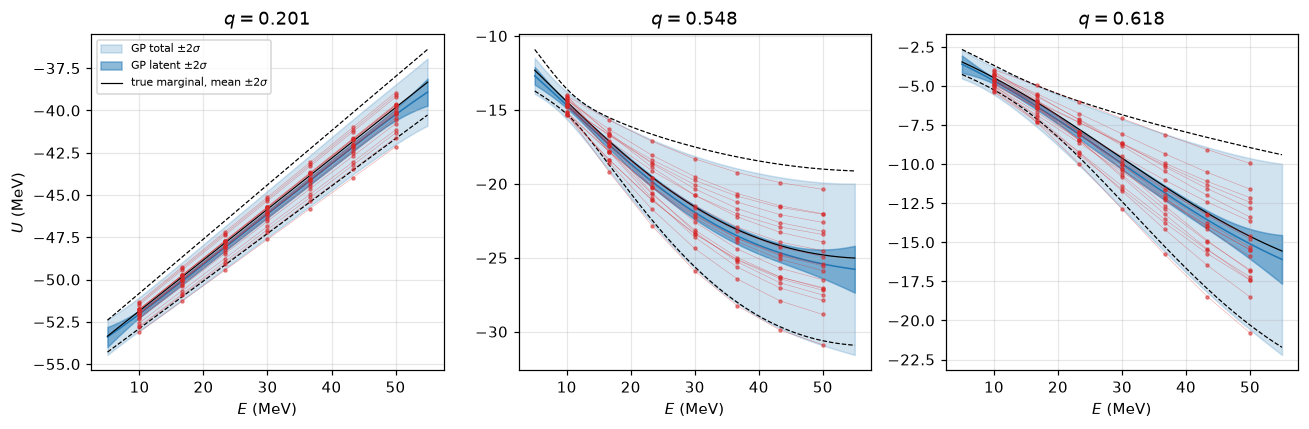

In [12]:
mean_f, sd_gp_f, W_f = gp.predict(E_fine)
sd_f = np.sqrt(sd_gp_f**2 + (1 + 1 / M) * propagate_var(W_f, Cov))
j_sl = [np.argmin(np.abs(q - v)) for v in [0.2, 0.55, 0.62]]
ref_f = U_theta(q[j_sl], E_fine, sample_theta(2000, seed=98))  # true marginal at the plotted q

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for c, (a, j) in enumerate(zip(ax, j_sl)):
    r = ref_f[..., c]
    a.fill_between(E_fine, mean_f[:, j] - 2 * sd_f[:, j], mean_f[:, j] + 2 * sd_f[:, j],
                   color="C0", alpha=0.2, label=r"GP total $\pm 2\sigma$")
    a.fill_between(E_fine, mean_f[:, j] - 2 * sd_gp_f[:, j], mean_f[:, j] + 2 * sd_gp_f[:, j],
                   color="C0", alpha=0.5, label=r"GP latent $\pm 2\sigma$")
    a.plot(E_fine, mean_f[:, j], "C0", lw=1)
    a.plot(E_fine, r.mean(0), "k", lw=0.8, label=r"true marginal, mean $\pm 2\sigma$")
    a.plot(E_fine, (r.mean(0) + 2 * np.outer([-1, 1], r.std(0))).T, "k--", lw=0.8)
    a.plot(E_train, members[:, :, j].T, "o-", color="C3", ms=2, lw=0.3, alpha=0.5)
    a.set_title(f"$q = {q[j]:.3f}$")
    a.set_xlabel("$E$ (MeV)")
ax[0].set_ylabel("$U$ (MeV)")
ax[0].legend(fontsize=7)
plt.tight_layout()

### Profiles at the test energies

How well do we interpolate whole curves $U(q,E_\ast)$ at new energies $E_\ast$?

- **Left:** the prediction (mean $\pm 2\sigma$, total) at the three test energies, against the true $\theta$-marginal (dashed).
- **Right:** a zoom on the surface at $E_\ast = 27$ MeV, where the $\theta$ spread is largest. Error of the predicted mean, with the predicted and true $\pm 2\sigma$.
- **Below:** the correlation in $q$ of the predictive covariance against the truth. The propagated term is what carries the $\theta$ correlations: draws that deepen the well, or move the edge, shift whole regions of the profile together.

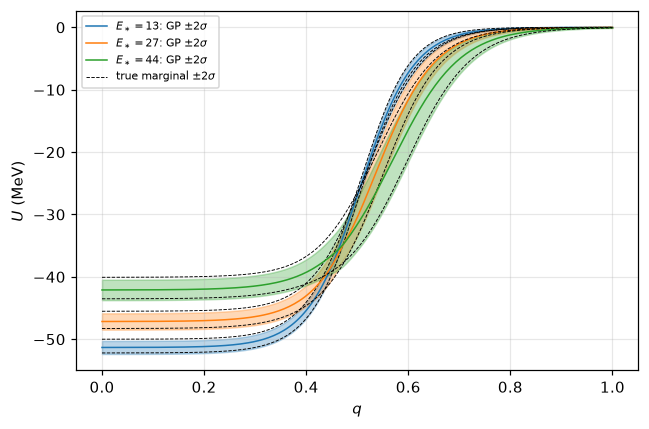

In [13]:
t_mean, t_sd = truth_test.mean(0), truth_test.std(0)
k = 1
fig = plt.figure(figsize=(6, 4))
for s_, (Es_, col) in enumerate(zip(E_test, ["C0", "C1", "C2"])):
    plt.fill_between(q, mean_test[s_] - 2 * sd_test[s_], mean_test[s_] + 2 * sd_test[s_], color=col, alpha=0.3)
    plt.plot(q, mean_test[s_], color=col, lw=1, label=rf"$E_\ast = {Es_:.0f}$: GP $\pm 2\sigma$")
    plt.plot(q, (t_mean[s_] + 2 * np.outer([-1, 1], t_sd[s_])).T, "k--", lw=0.6)
plt.plot([], [], "k--", lw=0.6, label=r"true marginal $\pm 2\sigma$")
plt.xlabel("$q$")
plt.ylabel("$U$ (MeV)")
plt.legend(fontsize=7)
plt.tight_layout()